# 01 · Data preparation and EDA

**Goal:** turn the raw Inside Airbnb Istanbul snapshot (25 Sep 2026, 27,232 listings × 90 columns) into one clean table that every other notebook and the app load.

**Steps**
1. Load and first look
2. Clean the price (the target)
3. Drop empty and leaky columns
4. Build our own `stay_type` (hotels hide as "Private room")
5. Listing features (bathrooms, amenities, host, reviews)
6. Location features (stations, restaurants, monuments)
7. EDA: what drives price?
8. Save `data/processed/listings_clean.parquet`

**Output:** `listings_clean.parquet` + `feature_lists.json`

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("..").resolve()          # repo root (notebooks/ is one level down)
sys.path.insert(0, str(ROOT))
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIGS = ROOT / "reports" / "figures"
for p in (PROCESSED, MODELS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
SEED = 42
from src.geo import PointIndex, load_points, haversine_m, ASIAN_DISTRICTS

## 1. Load and first look

In [2]:
df_raw = pd.read_csv(RAW / "listings.csv.gz")
print(df_raw.shape)
df_raw.head(3)

(27232, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,...,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,25436,https://www.airbnb.com/rooms/25436,20260925130056,2026-09-28,previous scrape,In the forest Sea view Two minutes to the city.,Our house is in Bebek Koru. If you want villag...,NaN,https://a0.muscache.com/pictures/b64c3ef0-2256...,105823,https://www.airbnb.com/users/show/105823,1462509707466640732,https://www.airbnb.com/users/profile/146250970...,Yesim,NaN,16,5,15,8,"İstanbul, Turkey","Merhabalar . Kuş sesi , akan su sesi ile uyan...",NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/067a8...,NaN,1,NaN,...,NaN,t,0,0,0,0,2026-09-28,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,34177,https://www.airbnb.com/rooms/34177,20260925130056,2026-09-28,previous scrape,PETIT HOUSE,My petit house is located in the bosphorous an...,NaN,https://a0.muscache.com/pictures/47356451/c288...,147330,https://www.airbnb.com/users/show/147330,1462510899379737925,https://www.airbnb.com/users/profile/146251089...,Ercan,NaN,16,3,15,8,"Istanbul, Turkey",grounded and well-traveled interior architect,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/147330/profil...,NaN,2,NaN,...,NaN,t,29,59,89,364,2026-09-28,16,0,0,94,0,0,0.0,2015-12-29,2024-01-03,4.69,4.69,4.88,4.88,4.81,4.69,4.81,NaN,NaN,2,2,0,0,0.12
2,42835,https://www.airbnb.com/rooms/42835,20260925130056,2026-09-28,previous scrape,Cozy apartment in the heart of Istanbul,Welcome to our cozy 2-bedroom apartment locate...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,187026,https://www.airbnb.com/users/show/187026,1462512109122697564,https://www.airbnb.com/users/profile/146251210...,Attila,NaN,16,1,15,8,"Istanbul, Turkey",I am from Istanbul/ Turkey. I will do my best ...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/187026/profil...,NaN,3,NaN,...,NaN,t,27,57,87,87,2026-09-28,0,0,0,87,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,1,2,0,NaN


In [3]:
# How empty is each column? (top 25)
missing = df_raw.isna().mean().sort_values(ascending=False)
missing.head(25).to_frame("missing_share")

,missing_share
neighborhood_overview,1.000000
host_since,1.000000
host_response_time,1.000000
host_thumbnail_url,1.000000
host_acceptance_rate,1.000000
host_response_rate,1.000000
host_verifications,1.000000
neighbourhood,1.000000
host_total_listings_count,1.000000
host_neighbourhood,1.000000


## 2. Clean the price

- The column says `$` but the values are **Turkish lira** (median ≈ ₺3,700). We treat everything as TRY.
- ~10% of listings have no price. They can't be used to train or to recommend, so we drop them.
- There are junk values (up to ₺4.99M per night). We cut extreme tails using percentiles.

In [4]:
df = df_raw.copy()
df["price"] = (df["price"].astype(str)
               .str.replace(r"[$,]", "", regex=True)
               .replace("nan", np.nan)
               .astype(float))
print(f"missing price: {df['price'].isna().mean():.1%}")
df = df.dropna(subset=["price"])
df["price"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .995]).round(0)

missing price: 9.8%


count      24553.0
mean        6022.0
std        38240.0
min           79.0
1%           417.0
5%           835.0
25%         2303.0
50%         3710.0
75%         6075.0
95%        13933.0
99%        38318.0
99.5%      55730.0
max      4989148.0
Name: price, dtype: float64

In [5]:
# Cutoff rule: keep 1st to 99.5th percentile. Change these two numbers if the EDA suggests otherwise.
LOW_Q, HIGH_Q = 0.01, 0.995
low, high = df["price"].quantile([LOW_Q, HIGH_Q])
before = len(df)
df = df[df["price"].between(low, high)].copy()
print(f"kept price between ₺{low:,.0f} and ₺{high:,.0f}: {before:,} -> {len(df):,} listings")
df["log_price"] = np.log(df["price"])

kept price between ₺417 and ₺55,730: 24,553 -> 24,190 listings


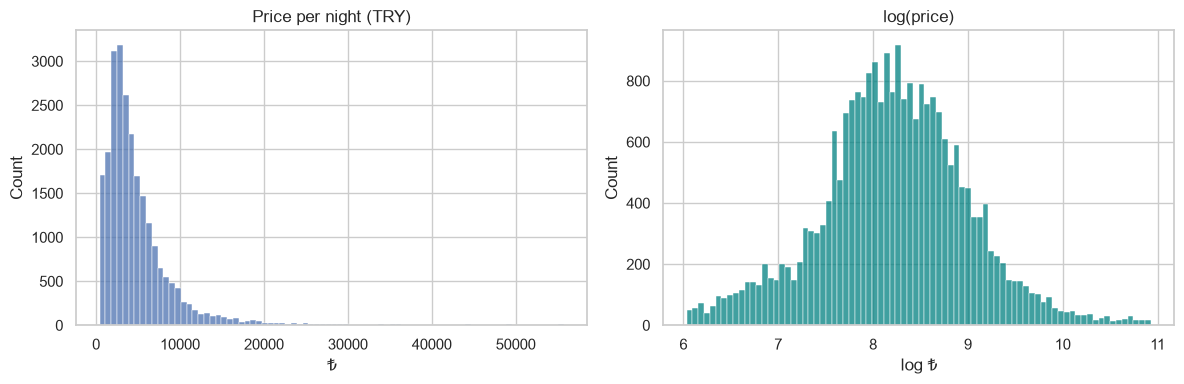

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=80, ax=ax[0]).set(title="Price per night (TRY)", xlabel="₺")
sns.histplot(df["log_price"], bins=80, ax=ax[1], color="teal").set(title="log(price)", xlabel="log ₺")
plt.tight_layout(); plt.savefig(FIGS / "price_distribution.png", dpi=120); plt.show()

> **Why log(price)?** The raw price is very right-skewed. The log is close to a bell shape, so models fit it better and errors become *percentages* instead of lira.

## 3. Drop empty and leaky columns

- **Empty:** columns that are 100% missing in this snapshot (`host_since`, response/acceptance rate, `bathrooms`, `neighbourhood`, `calendar_updated`, …).
- **Leaky:** `estimated_occupancy_l365d` and `estimated_revenue_l365d` are *computed from reviews and price*. Using them to predict price or reliability would be cheating.
- **Useless for ML:** URLs, scrape metadata, long free text.

In [7]:
empty_cols = [c for c in df.columns if df[c].isna().all()]
leaky_cols = ["estimated_occupancy_l365d", "estimated_revenue_l365d"]
useless_cols = ["listing_url", "scrape_id", "last_scraped", "source", "description",
                "neighborhood_overview", "host_url", "host_profile_id", "host_profile_url",
                "host_name", "host_location", "host_about", "host_thumbnail_url",
                "host_picture_url", "host_neighbourhood", "host_verifications",
                "calendar_last_scraped", "price_quote_raw", "license",
                "neighbourhood_group_cleansed"]
drop = [c for c in set(empty_cols + leaky_cols + useless_cols) if c in df.columns]
df = df.drop(columns=drop)
print(f"dropped {len(drop)} columns -> {df.shape[1]} left")
print("empty:", sorted(empty_cols))

dropped 31 columns -> 60 left
empty: ['bathrooms', 'calendar_updated', 'host_acceptance_rate', 'host_neighbourhood', 'host_response_rate', 'host_response_time', 'host_since', 'host_thumbnail_url', 'host_total_listings_count', 'host_verifications', 'instant_bookable', 'neighborhood_overview', 'neighbourhood', 'neighbourhood_group_cleansed']


## 4. Our own `stay_type`

`room_type` hides ~3,500 hotel rooms under "Private room". `property_type` is more honest ("Room in hotel", "Room in boutique hotel"…), so we group it into 5 types a guest understands.

In [8]:
def stay_type(row):
    p = str(row["property_type"]).lower()
    if "hostel" in p or row["room_type"] == "Shared room" or "shared room" in p:
        return "Hostel / shared"
    if "serviced apartment" in p or "aparthotel" in p:
        return "Serviced apt"
    if "hotel" in p or row["room_type"] == "Hotel room":
        return "Hotel room"
    if row["room_type"] == "Entire home/apt":
        return "Entire home"
    return "Private room"

df["stay_type"] = df.apply(stay_type, axis=1)
pd.crosstab(df["stay_type"], df["room_type"], margins=True)

room_type,Entire home/apt,Hotel room,Private room,Shared room,All
stay_type,,,,,
Entire home,15252,0,0,0,15252
Hostel / shared,0,4,10,147,161
Hotel room,1,223,3816,0,4040
Private room,0,0,3031,0,3031
Serviced apt,1410,30,266,0,1706
All,16663,257,7123,147,24190


## 5. Listing features

In [9]:
# Bathrooms: "1.5 shared baths" -> 1.5 and a shared flag. "Half-bath" -> 0.5
bt = df["bathrooms_text"].fillna("").str.lower()
df["bathrooms_n"] = pd.to_numeric(bt.str.extract(r"([\d.]+)")[0], errors="coerce")
df.loc[bt.str.contains("half"), "bathrooms_n"] = 0.5
df["is_shared_bath"] = bt.str.contains("shared").astype(int)

# Bedrooms / beds: fill gaps with the median for the same number of guests
for col in ["bedrooms", "beds", "bathrooms_n"]:
    df[col] = df[col].fillna(df.groupby("accommodates")[col].transform("median")).fillna(1)
    df[col] = df[col].clip(upper=10)   # a few listings claim 50 bedrooms / 67 beds

# Host
df["is_superhost"] = (df["host_is_superhost"] == "t").astype(int)
df["host_identity_verified"] = (df["host_identity_verified"] == "t").astype(int)
df["host_years"] = df["hosts_time_as_host_years"].fillna(0)
df["host_listings"] = df["calculated_host_listings_count"].fillna(1)

# Minimum nights: flag disguised monthly rentals
df["is_monthly"] = (df["minimum_nights"] >= 28).astype(int)
df["min_nights_capped"] = df["minimum_nights"].clip(upper=30)
print(f"monthly-style listings: {df['is_monthly'].mean():.1%}")

monthly-style listings: 32.1%


In [10]:
# Amenities: the column is a JSON list of strings
amen = df["amenities"].apply(lambda s: [a.lower() for a in json.loads(s)] if isinstance(s, str) else [])
df["n_amenities"] = amen.apply(len)

AMENITY_FLAGS = {
    "has_wifi":        lambda a: any("wifi" in x for x in a),
    "has_ac":          lambda a: any("air conditioning" in x for x in a),
    "has_kitchen":     lambda a: "kitchen" in a,
    "has_washer":      lambda a: any(x.startswith("washer") or "free washer" in x for x in a),
    "has_workspace":   lambda a: any("dedicated workspace" in x for x in a),
    "has_self_checkin":lambda a: "self check-in" in a,
    "has_elevator":    lambda a: "elevator" in a,
    "has_parking":     lambda a: any("free parking" in x for x in a),
    "has_balcony":     lambda a: any("balcony" in x or "patio" in x for x in a),
    "has_sea_view":    lambda a: any(k in x for x in a for k in ("sea view", "bosphorus", "waterfront", "ocean view")),
    "has_dishwasher":  lambda a: "dishwasher" in a,
    "has_tv":          lambda a: any(x == "tv" or x.startswith("hdtv") or x.startswith("tv with") for x in a),
}
for name, fn in AMENITY_FLAGS.items():
    df[name] = amen.apply(fn).astype(int)
df[list(AMENITY_FLAGS)].mean().sort_values(ascending=False).round(3).to_frame("share")

,share
has_wifi,0.967
has_tv,0.821
has_kitchen,0.763
has_ac,0.726
has_washer,0.693
has_workspace,0.582
has_self_checkin,0.427
has_parking,0.308
has_dishwasher,0.300
has_elevator,0.295


In [11]:
# Reviews: rating shrunk toward the city average so "5.0 from 2 reviews" doesn't beat "4.9 from 300"
df["has_reviews"] = (df["number_of_reviews"] > 0).astype(int)
PRIOR_N = 10
city_mean = df.loc[df["has_reviews"] == 1, "review_scores_rating"].mean()
n = df["number_of_reviews"]
df["rating_shrunk"] = ((n * df["review_scores_rating"].fillna(city_mean) + PRIOR_N * city_mean)
                       / (n + PRIOR_N))
print(f"city mean rating {city_mean:.2f}; listings with reviews: {df['has_reviews'].mean():.1%}")

# Reliability target for notebook 04: at least one review in the last 12 months
df["active_ltm"] = (df["number_of_reviews_ltm"] > 0).astype(int)
print(f"active in last 12 months: {df['active_ltm'].mean():.1%}")

city mean rating 4.58; listings with reviews: 66.7%
active in last 12 months: 49.3%


## 6. Location features

Location is the biggest driver of price in a city, so we describe it in several ways:
- **district** and **side** (Europe / Asia)
- distance to the two tourist hearts: **Sultanahmet** (Hagia Sophia) and **Taksim**
- distance to the **nearest metro/tram/ferry stop** and how many are within 500 m
- how many **restaurants** are within 500 m (a proxy for "lively area")
- distance to the **nearest monument** from our list

In [12]:
latlon = df[["latitude", "longitude"]].to_numpy()

df["is_asia"] = df["neighbourhood_cleansed"].isin(ASIAN_DISTRICTS).astype(int)
df["dist_sultanahmet_m"] = haversine_m(df["latitude"], df["longitude"], 41.00858, 28.98017)
df["dist_taksim_m"] = haversine_m(df["latitude"], df["longitude"], 41.03700, 28.98500)

stations, _ = load_points(RAW / "stations.geojson")
st_idx = PointIndex(stations)
df["dist_station_m"] = st_idx.nearest_m(latlon)
df["stations_500m"] = st_idx.count_within(latlon, 500)

rest_eu, _ = load_points(RAW / "restaurants_eu.geojson")
rest_as, _ = load_points(RAW / "restaurants_asia.geojson")
restaurants = np.unique(np.round(np.vstack([rest_eu, rest_as]), 6), axis=0)  # the two boxes overlap
df["restaurants_500m"] = PointIndex(restaurants).count_within(latlon, 500)

monuments = pd.read_csv(RAW / "monuments.csv")
df["dist_monument_m"] = PointIndex(monuments[["lat", "lon"]].to_numpy()).nearest_m(latlon)

print(f"{len(stations)} stations, {len(restaurants)} restaurants, {len(monuments)} monuments")
df[["dist_sultanahmet_m", "dist_station_m", "stations_500m", "restaurants_500m", "dist_monument_m"]].describe().round(0)

555 stations, 7983 restaurants, 31 monuments


,dist_sultanahmet_m,dist_station_m,stations_500m,restaurants_500m,dist_monument_m
count,24190.0,24190.0,24190.0,24190.0,24190.0
mean,8578.0,1436.0,3.0,110.0,4945.0
std,11008.0,5179.0,3.0,117.0,9750.0
min,27.0,1.0,0.0,0.0,8.0
25%,2767.0,236.0,0.0,3.0,367.0
50%,4413.0,389.0,1.0,62.0,833.0
75%,10289.0,701.0,4.0,199.0,4625.0
max,82747.0,49689.0,24.0,438.0,78133.0


## 7. EDA: what drives price?

For each chart, write 1–2 sentences under it on what you see. These sentences go straight into the slides.

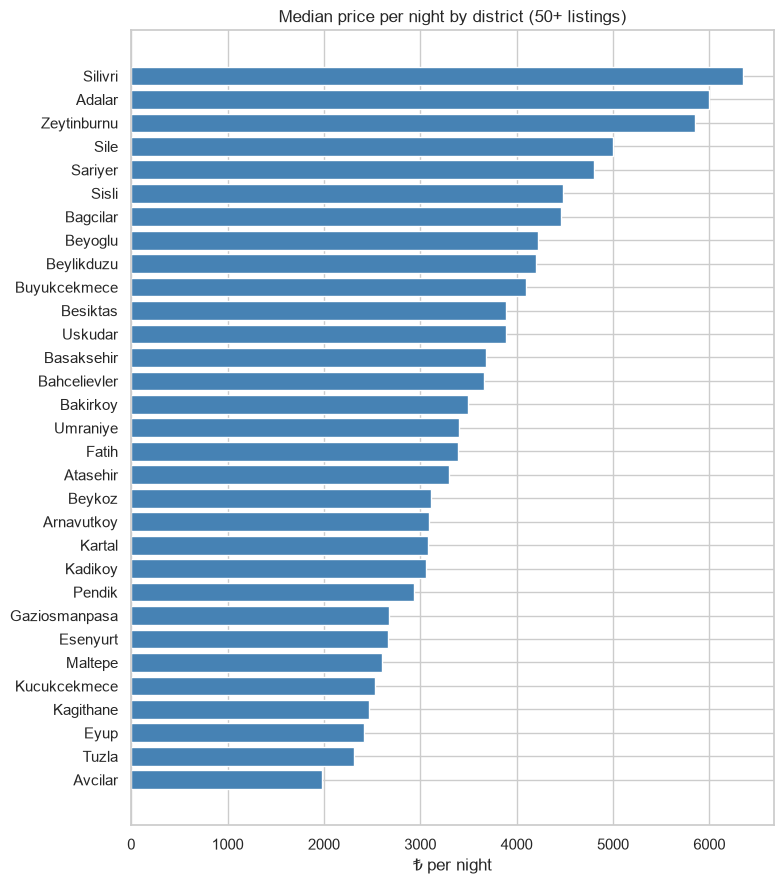

districts with <50 listings: {'Cekmekoy': 42, 'Bayrampasa': 35, 'Gungoren': 28, 'Catalca': 23, 'Sancaktepe': 23, 'Esenler': 18, 'Sultanbeyli': 14, 'Sultangazi': 13}


In [13]:
# 7.1 Median price by district (districts with 50+ listings)
by_d = (df.groupby("neighbourhood_cleansed")["price"]
          .agg(["median", "count"]).query("count >= 50").sort_values("median"))
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(by_d.index, by_d["median"], color="steelblue")
ax.set(title="Median price per night by district (50+ listings)", xlabel="₺ per night")
plt.tight_layout(); plt.savefig(FIGS / "price_by_district.png", dpi=120); plt.show()
print("districts with <50 listings:", df["neighbourhood_cleansed"].value_counts().loc[lambda s: s < 50].to_dict())

**What I see:** _…_

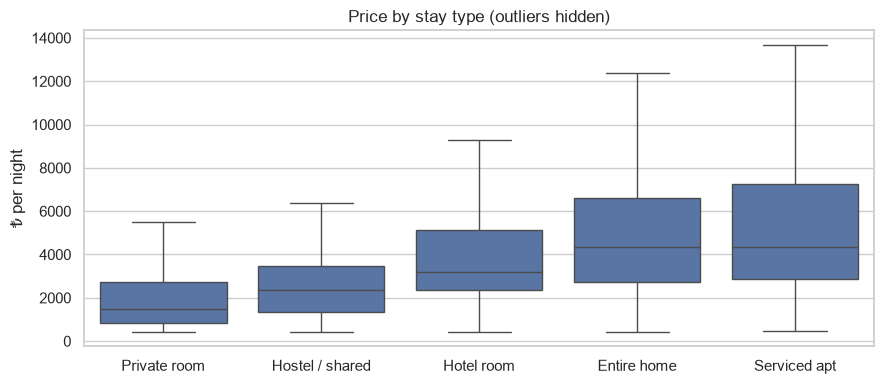

,count,median
stay_type,,
Entire home,15252,4329.0
Hostel / shared,161,2375.0
Hotel room,4040,3215.0
Private room,3031,1473.0
Serviced apt,1706,4347.0


In [14]:
# 7.2 Price by stay type
order = df.groupby("stay_type")["price"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df, x="stay_type", y="price", order=order, showfliers=False, ax=ax)
ax.set(title="Price by stay type (outliers hidden)", ylabel="₺ per night", xlabel="")
plt.tight_layout(); plt.savefig(FIGS / "price_by_stay_type.png", dpi=120); plt.show()
df.groupby("stay_type")["price"].agg(["count", "median"]).round(0)

**What I see:** _…_

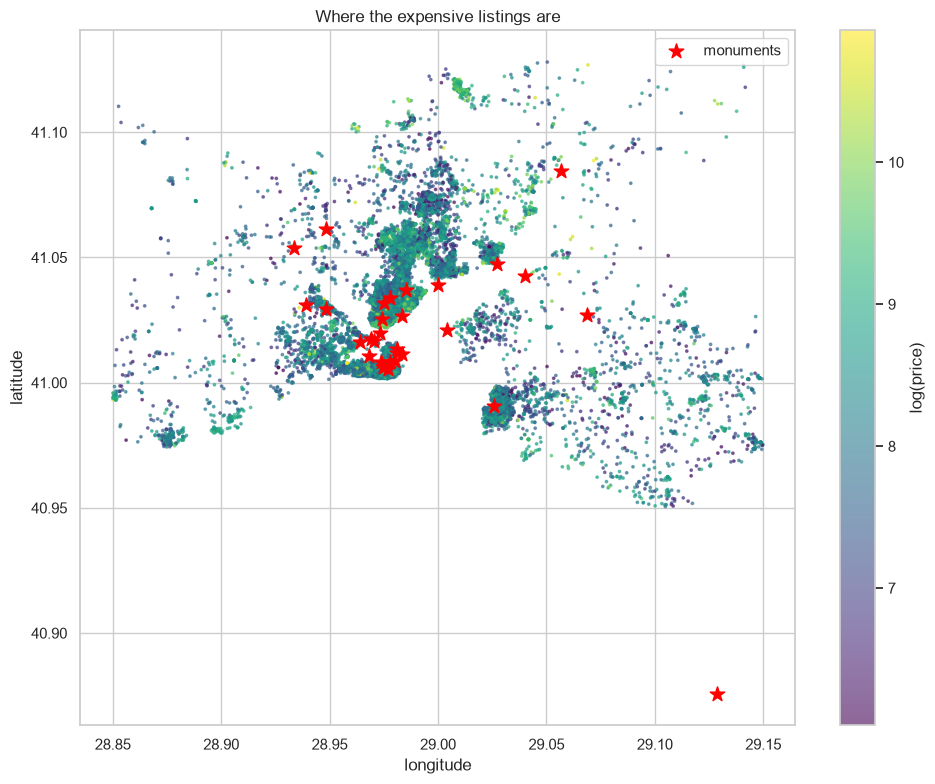

In [15]:
# 7.3 Map of listings coloured by log(price), central Istanbul
central = df[df["latitude"].between(40.95, 41.13) & df["longitude"].between(28.85, 29.15)]
fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(central["longitude"], central["latitude"], c=central["log_price"],
                s=3, cmap="viridis", alpha=.6)
ax.scatter(monuments["lon"], monuments["lat"], marker="*", s=120, c="red", label="monuments")
plt.colorbar(sc, label="log(price)"); ax.legend()
ax.set(title="Where the expensive listings are", xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.savefig(FIGS / "price_map.png", dpi=120); plt.show()

**What I see:** _…_

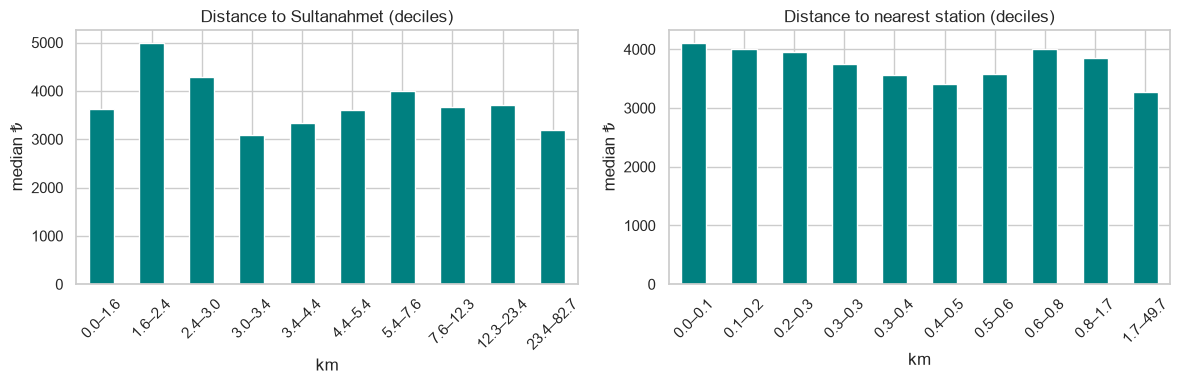

In [16]:
# 7.4 Does being close to Sultanahmet or a station matter?
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col, title in [(ax[0], "dist_sultanahmet_m", "Distance to Sultanahmet"),
                      (ax[1], "dist_station_m", "Distance to nearest station")]:
    bins = pd.qcut(df[col] / 1000, 10)
    med = df.groupby(bins, observed=True)["price"].median()
    med.index = [f"{iv.left:.1f}–{iv.right:.1f}" for iv in med.index]
    med.plot(kind="bar", ax=a, color="teal")
    a.set(title=title + " (deciles)", ylabel="median ₺", xlabel="km")
    a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIGS / "price_vs_distance.png", dpi=120); plt.show()

**What I see:** _…_

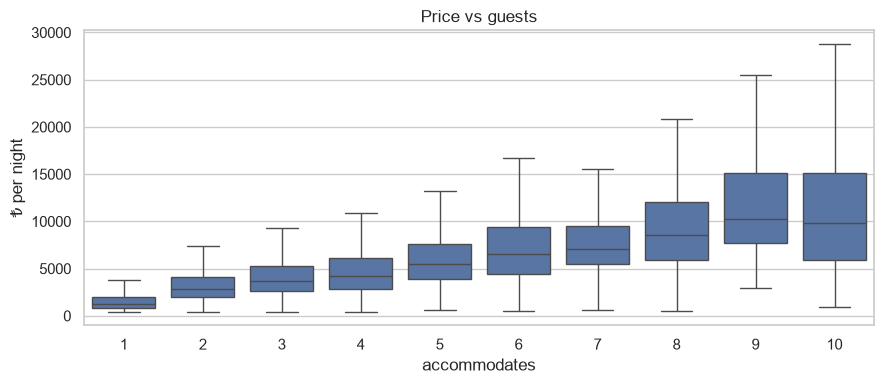

In [17]:
# 7.5 Size: price vs number of guests
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df[df["accommodates"] <= 10], x="accommodates", y="price", showfliers=False, ax=ax)
ax.set(title="Price vs guests", ylabel="₺ per night")
plt.tight_layout(); plt.savefig(FIGS / "price_vs_guests.png", dpi=120); plt.show()

**What I see:** _…_

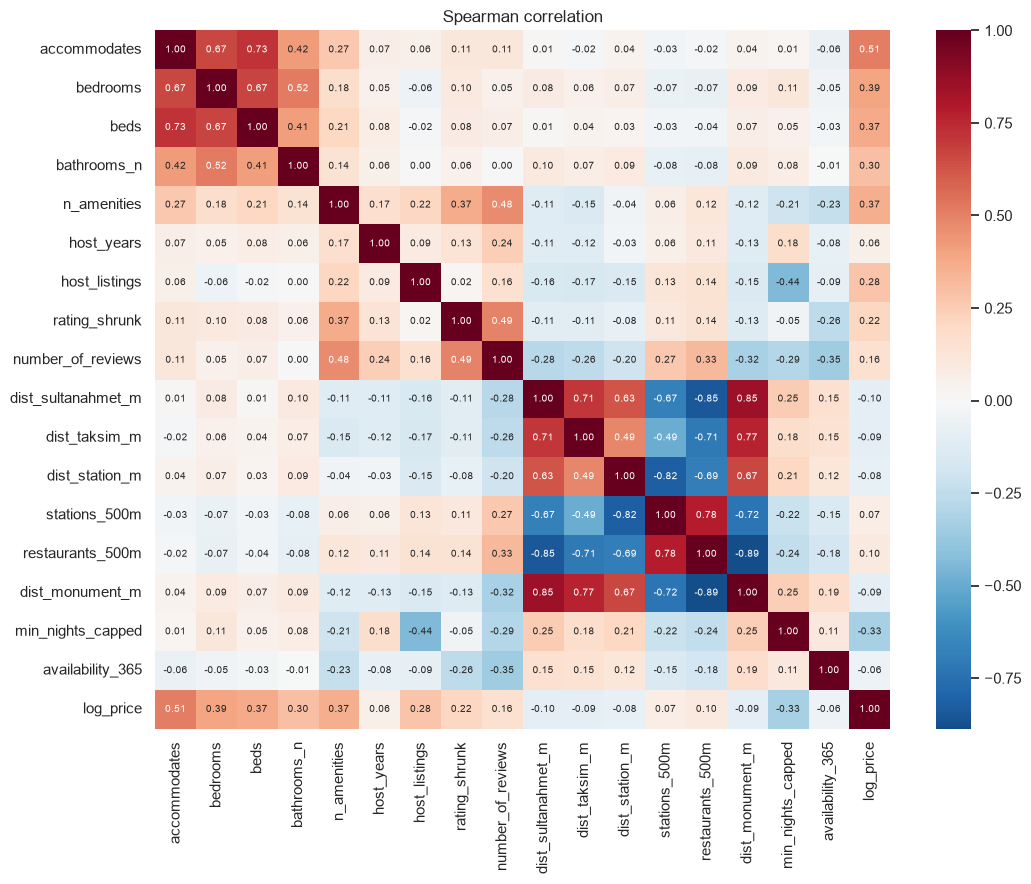

min_nights_capped    -0.33
dist_sultanahmet_m   -0.10
dist_monument_m      -0.09
dist_taksim_m        -0.09
dist_station_m       -0.08
availability_365     -0.06
host_years            0.06
stations_500m         0.07
restaurants_500m      0.10
number_of_reviews     0.16
rating_shrunk         0.22
host_listings         0.28
bathrooms_n           0.30
n_amenities           0.37
beds                  0.37
bedrooms              0.39
accommodates          0.51
Name: log_price, dtype: float64

In [18]:
# 7.6 Correlation of numeric features with log(price)
num_cols = ["accommodates", "bedrooms", "beds", "bathrooms_n", "n_amenities", "host_years",
            "host_listings", "rating_shrunk", "number_of_reviews", "dist_sultanahmet_m",
            "dist_taksim_m", "dist_station_m", "stations_500m", "restaurants_500m",
            "dist_monument_m", "min_nights_capped", "availability_365", "log_price"]
corr = df[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set(title="Spearman correlation")
plt.tight_layout(); plt.savefig(FIGS / "correlation.png", dpi=120); plt.show()
corr["log_price"].drop("log_price").sort_values().round(2)

**What I see:** _…_

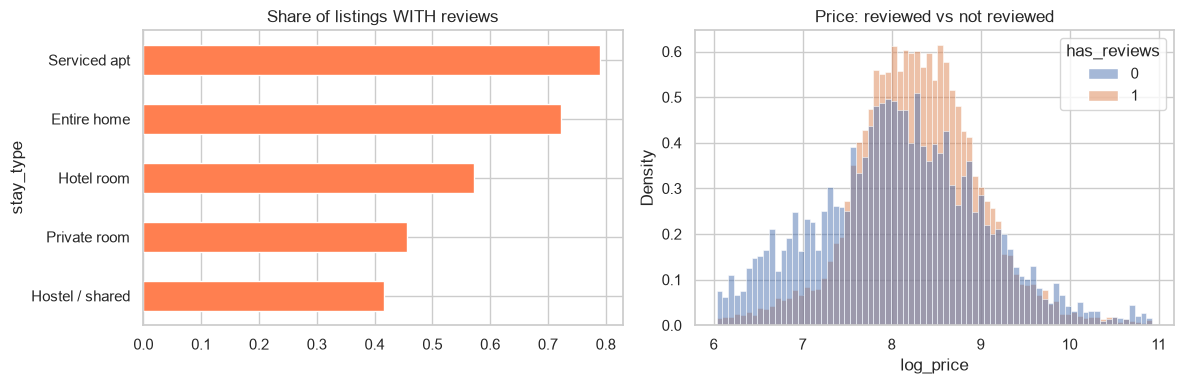

no reviews: 33.3%


In [19]:
# 7.7 The review gap: who has no reviews?
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("stay_type")["has_reviews"].mean().sort_values().plot(kind="barh", ax=ax[0], color="coral")
ax[0].set(title="Share of listings WITH reviews", xlabel="")
sns.histplot(data=df, x="log_price", hue="has_reviews", stat="density", common_norm=False, ax=ax[1])
ax[1].set(title="Price: reviewed vs not reviewed")
plt.tight_layout(); plt.savefig(FIGS / "review_gap.png", dpi=120); plt.show()
print(f"no reviews: {(1 - df['has_reviews'].mean()):.1%}")

**What I see:** _…_ (this is why notebook 04 exists)

In [20]:
# 7.8 Amenities: median price with vs without each one
rows = []
for f in AMENITY_FLAGS:
    w, wo = df.loc[df[f] == 1, "price"].median(), df.loc[df[f] == 0, "price"].median()
    rows.append((f, df[f].mean(), w, wo, w / wo - 1))
pd.DataFrame(rows, columns=["amenity", "share", "median_with", "median_without", "uplift"]) \
  .sort_values("uplift", ascending=False).round(2)

,amenity,share,median_with,median_without,uplift
10,has_dishwasher,0.30,5512.61,3167.33,0.74
0,has_wifi,0.97,3773.05,2430.00,0.55
6,has_elevator,0.30,4910.10,3288.20,0.49
8,has_balcony,0.23,5099.50,3428.67,0.49
1,has_ac,0.73,4065.33,2743.00,0.48
9,has_sea_view,0.07,5239.00,3628.26,0.44
2,has_kitchen,0.76,4013.00,3065.50,0.31
3,has_washer,0.69,4123.94,3160.70,0.30
5,has_self_checkin,0.43,4267.05,3300.00,0.29
11,has_tv,0.82,3796.00,3233.00,0.17


**What I see:** _…_ (careful: uplift is a correlation, a sea view also means a pricier area)

## 8. Save the clean table

In [21]:
CAT_FEATURES = ["neighbourhood_cleansed", "stay_type", "room_type"]
NUM_FEATURES = ["accommodates", "bedrooms", "beds", "bathrooms_n", "is_shared_bath",
                "n_amenities", *AMENITY_FLAGS, "is_superhost", "host_identity_verified",
                "host_years", "host_listings", "min_nights_capped", "availability_365",
                "rating_shrunk", "has_reviews", "latitude", "longitude", "is_asia",
                "dist_sultanahmet_m", "dist_taksim_m", "dist_station_m", "stations_500m",
                "restaurants_500m", "dist_monument_m"]
# Columns that come from reviews: allowed for price, NOT allowed for the reliability classifier
REVIEW_COLS = ["rating_shrunk", "has_reviews", "number_of_reviews", "number_of_reviews_ltm",
               "number_of_reviews_l30d", "number_of_reviews_ly", "reviews_per_month",
               "first_review", "last_review"] + [c for c in df.columns if c.startswith("review_scores")]
APP_COLS = ["id", "name", "picture_url", "host_id", "property_type", "price", "log_price",
            "minimum_nights", "maximum_nights", "is_monthly", "has_availability",
            "availability_30", "number_of_reviews", "number_of_reviews_ltm", "review_scores_rating",
            "active_ltm", "price_quote_checkin_date"]

keep = list(dict.fromkeys(APP_COLS + CAT_FEATURES + NUM_FEATURES + REVIEW_COLS))
clean = df[[c for c in keep if c in df.columns]].reset_index(drop=True)
clean.to_parquet(PROCESSED / "listings_clean.parquet", index=False)
json.dump({"cat": CAT_FEATURES, "num": NUM_FEATURES, "review": REVIEW_COLS},
          open(PROCESSED / "feature_lists.json", "w"), indent=2)
print(clean.shape, "saved to", PROCESSED / "listings_clean.parquet")

(24190, 66) saved to C:\Users\Hello\Desktop\NTI\FinalNTI project\data\processed\listings_clean.parquet


### Summary (fill in)
- Listings kept: _…_
- Biggest price drivers from EDA: _…_
- Data problems found and how we handled them: price in TRY despite "$", 14 empty columns, leakage columns, hotels hidden as private rooms, 35% without reviews.